<h1 align = "Center">
Lotus Group Customer Value & Profitability Analysis

<h2 align = "Center">
Machine Learning Part A — Customer Value Segmentation
</h2>
</h1>

**Research question 2:** *What distinct customer segments exist, and what is each worth?*

We use **K-Means clustering**, an unsupervised machine-learning method that groups customers who behave alike. There is no "right answer" to predict, so we judge the result against the success criteria we set in the project charter **before** modelling:

| Criterion | Target |
|---|---|
| Number of segments | 3–6 |
| Separation (silhouette score) | ≥ 0.30 |
| Minimum segment size | ≥ 5% of customers |
| Stability | Same segments when re-run with different random seeds and on resampled data |
| Usefulness | Every segment has a clear business name and a recommended action |

The segments describe how customers **have** bought. They guide prioritisation and marketing; they are not a forecast of what each customer will do next.

# Setup and Data Loading

In [1]:
import pandas as pd
from pathlib import Path

features_path = Path("../01_Data/features")
outputs_path = Path("../01_Data/outputs")
images_path = Path("../05_Images")
outputs_path.mkdir(parents=True, exist_ok=True)
images_path.mkdir(parents=True, exist_ok=True)

customer_features = pd.read_csv(features_path / "customer_features.csv")

RANDOM_STATE = 42

print("Customers:", len(customer_features))
print("Customers with a sale:", customer_features["has_sale"].sum())
print("Registered, never purchased:", (~customer_features["has_sale"]).sum())

Customers: 3000
Customers with a sale: 2908
Registered, never purchased: 92

Customers without a qualifying sale have no purchase behaviour to group, so we set them aside now and report them as their own group at the end.

In [2]:
buyers = customer_features[customer_features["has_sale"]].copy().reset_index(drop=True)
never_purchased = customer_features[~customer_features["has_sale"]].copy()

print("Customers to segment:", len(buyers))

Customers to segment: 2908

### Chart style

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

NAVY = "#00274B"
MUTED = "#6B7280"
percent = FuncFormatter(lambda v, _: f"{v:.0%}")

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#a3a29c",
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "lines.linewidth": 2,
})

# Choosing the Features

The exploratory analysis and the feature engineering notebook told us three things that shape this choice:

1. **Revenue is extremely skewed**, so we use its logarithm. Otherwise a handful of very large spenders would dominate the clustering.
2. **Revenue, profit and Electronics share move closely together.** Using all three would count the same idea several times.
3. **Electronics share splits customers into two natural groups**: those who never buy Electronics and those for whom Electronics are most of their spend.

We compare three candidate feature sets, each covering *value*, *product mix* and *engagement* in a different way:

| Set | Features | Idea |
|---|---|---|
| Broad | log revenue, profit margin, orders per year, recency, average discount | Many angles on each customer |
| Mix + frequency | log revenue, Electronics share, recency, number of orders | Adds purchase count |
| **Compact** | **log revenue, Electronics share, recency** | **One feature each for value, mix and engagement** |

In [4]:
import numpy as np

buyers["log_revenue"] = np.log10(buyers["total_revenue"])

candidate_sets = {
    "Broad": ["log_revenue", "profit_margin", "orders_per_year", "recency_days", "average_discount"],
    "Mix + frequency": ["log_revenue", "electronics_share", "recency_days", "orders"],
    "Compact": ["log_revenue", "electronics_share", "recency_days"],
}

Every feature is **standardised** (rescaled to mean 0 and standard deviation 1) before clustering. K-Means measures distance, and without scaling, recency (measured in hundreds of days) would outweigh Electronics share (0 to 1).

For each candidate set we try 3 to 6 segments and record the success-criteria metrics.

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

comparison = []
for set_name, columns in candidate_sets.items():
    X = StandardScaler().fit_transform(buyers[columns])
    for k in range(3, 7):
        labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
        comparison.append({
            "feature set": set_name,
            "segments": k,
            "silhouette": silhouette_score(X, labels),
            "smallest segment": np.bincount(labels).min() / len(labels),
        })

comparison = pd.DataFrame(comparison)
(
    comparison.pivot(index="feature set", columns="segments", values="silhouette")
    .loc[list(candidate_sets)]
    .style.format("{:.3f}")
    .highlight_between(left=0.30, right=1, color="#d8ecd9")
)

segments,3,4,5,6
feature set,,,,
Broad,0.281,0.282,0.293,0.295
Mix + frequency,0.374,0.330,0.304,0.317
Compact,0.489,0.459,0.401,0.354


**Reading the table:** the green cells meet the silhouette target of 0.30.

- The **Broad** set never separates customers clearly. Profit margin, orders per year and discount add noise rather than structure.
- **Mix + frequency** passes only at 3–4 segments.
- The **Compact** set gives the clearest separation at every number of segments.

We choose the **Compact** set: **log revenue, Electronics share and recency**. It is also the easiest to explain to a business audience. Each customer is described by *how much they spend*, *what they buy* and *how recently they bought*.

Profit, margin, frequency and discounts are not thrown away. We use them to **describe** the segments after they are formed.

In [6]:
cluster_features = candidate_sets["Compact"]

scaler = StandardScaler()
X = scaler.fit_transform(buyers[cluster_features])

pd.DataFrame(X, columns=cluster_features).describe().loc[["mean", "std"]].round(2)

,log_revenue,electronics_share,recency_days
mean,0.0,-0.0,0.0
std,1.0,1.0,1.0


# Choosing the Number of Segments

We use two standard measures:

- **Inertia (elbow method):** how tightly customers sit around their segment centre. It always falls as we add segments; we look for the point where adding more stops helping much.
- **Silhouette score:** how clearly each customer belongs to its own segment rather than a neighbouring one (−1 to 1; higher is better).

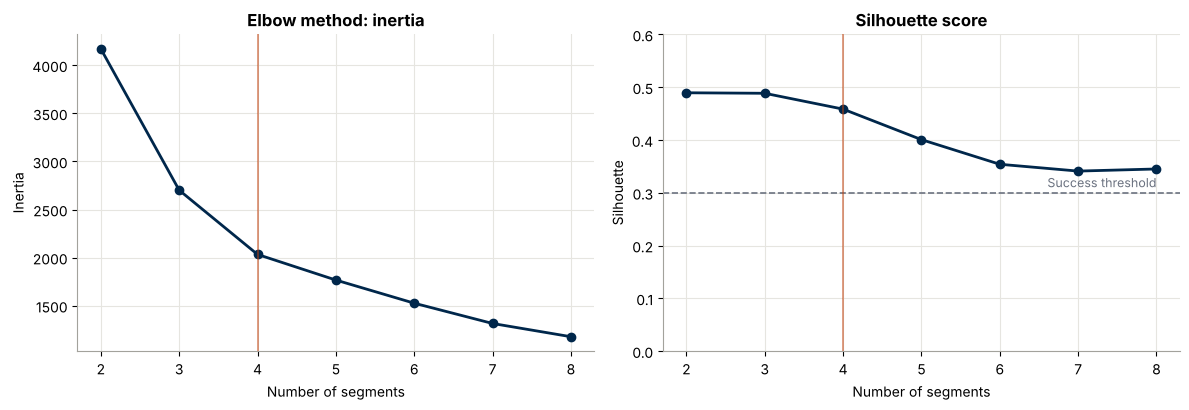

,inertia,silhouette
segments,,
2,4169.978,0.490
3,2700.528,0.489
4,2032.749,0.459
5,1766.412,0.401
6,1525.813,0.354
7,1315.003,0.341
8,1177.362,0.345


In [7]:
k_values = range(2, 9)
inertia, silhouette = [], []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(list(k_values), inertia, color=NAVY, marker="o")
axes[0].set(title="Elbow method: inertia", xlabel="Number of segments", ylabel="Inertia")

axes[1].plot(list(k_values), silhouette, color=NAVY, marker="o")
axes[1].axhline(0.30, color=MUTED, linestyle="--", linewidth=1.2)
axes[1].text(8, 0.305, "Success threshold", color=MUTED, ha="right", va="bottom", fontsize=9)
axes[1].set(title="Silhouette score", xlabel="Number of segments", ylabel="Silhouette", ylim=(0, 0.6))

for ax in axes:
    ax.axvline(4, color="#C2410C", linewidth=1.2, alpha=0.6)
    ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

pd.DataFrame({"segments": list(k_values), "inertia": inertia, "silhouette": silhouette}).set_index("segments").round(3)

The elbow bends at **3–4 segments**, and the silhouette stays high (around 0.46–0.49) up to 4 segments before falling away. The statistics alone can't separate 3 from 4, so we compare what each choice means for the business.

In [8]:
def profile(labels):
    return (
        buyers.assign(segment=labels)
        .groupby("segment")
        .agg(customers=("customer_id", "size"),
             median_revenue=("total_revenue", "median"),
             median_electronics_share=("electronics_share", "median"),
             median_recency_days=("recency_days", "median"),
             total_revenue=("total_revenue", "sum"))
        .sort_values("total_revenue", ascending=False)
    )

for k in (3, 4, 5):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    print(f"\n{k} segments")
    print(profile(labels).round(2).to_string())


3 segments
         customers  median_revenue  median_electronics_share  median_recency_days  total_revenue
segment                                                                                         
1             1297        20358.00                      0.85                169.0     34705434.5
0             1123         3235.00                      0.00                138.0      4066263.5
2              488         1752.75                      0.00                642.0      1284602.5

4 segments
         customers  median_revenue  median_electronics_share  median_recency_days  total_revenue
segment                                                                                         
1             1006        21227.25                      0.85                119.0     28184854.5
3              340        16686.00                      0.87                488.5      6928050.5
0             1097         3293.50                      0.00                136.0      4017173.0
2     

**Why 4 segments:**

- With **3 segments**, customers who used to buy Electronics but haven't bought in over a year are merged with active Electronics buyers. That group spent **EGP 6.9M** and is the most valuable one to win back, so hiding it would lose the most useful insight.
- With **4 segments**, they get their own group.
- With **5 segments**, the lapsed Clothing customers are split into "lapsed" and "very lapsed". That adds detail but no new action, and the silhouette drops to 0.40.

We therefore choose **4 segments**. The choice is supported by the statistics and by the business case.

# Fitting the Final Model

In [9]:
kmeans = KMeans(n_clusters=4, n_init=50, random_state=RANDOM_STATE)
buyers["cluster"] = kmeans.fit_predict(X)

final_silhouette = silhouette_score(X, buyers["cluster"])
print(f"Silhouette score: {final_silhouette:.3f}")
print("\nCustomers per cluster:")
print(buyers["cluster"].value_counts().sort_index().to_string())

Silhouette score: 0.459

Customers per cluster:
cluster
0    1097
1    1006
2     465
3     340

### Naming the segments

K-Means numbers its clusters arbitrarily, and the numbers can change between runs. We therefore name each segment from its **centre** (in original units), using two plain rules:

- **Electronics vs Clothing:** is the segment's typical Electronics share above or below 50%?
- **Active vs Lapsed:** has the typical customer bought within the last year (365 days)?

This makes the names reproducible: the same customers always get the same name.

In [10]:
centres = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_), columns=cluster_features
)
centres["revenue_at_centre"] = 10 ** centres["log_revenue"]

def name_segment(row):
    buyer_type = "Electronics Buyers" if row["electronics_share"] >= 0.5 else "Clothing Shoppers"
    status = "Active" if row["recency_days"] <= 365 else "Lapsed"
    return f"{status} {buyer_type}"

centres["segment"] = centres.apply(name_segment, axis=1)
buyers["segment"] = buyers["cluster"].map(centres["segment"])

centres[["segment", "revenue_at_centre", "electronics_share", "recency_days"]].round(2)

,segment,revenue_at_centre,electronics_share,recency_days
0,Active Clothing Shoppers,2875.69,0.05,155.95
1,Active Electronics Buyers,22211.77,0.80,135.73
2,Lapsed Clothing Shoppers,1396.07,0.02,646.86
3,Lapsed Electronics Buyers,15977.01,0.82,542.96


In [11]:
assert centres["segment"].nunique() == 4, "Each cluster must receive a different name"

SEGMENT_ORDER = [
    "Active Electronics Buyers",
    "Lapsed Electronics Buyers",
    "Active Clothing Shoppers",
    "Lapsed Clothing Shoppers",
]
SEGMENT_COLORS = {
    "Active Electronics Buyers": "#1F5F99",
    "Lapsed Electronics Buyers": "#6FA8E0",
    "Active Clothing Shoppers": "#9C3D74",
    "Lapsed Clothing Shoppers": "#D98BB5",
}
print("Each cluster has a unique name.")

Each cluster has a unique name.

Colours follow the meaning of each segment: **blue for Electronics, magenta for Clothing** (as in the exploratory analysis), **dark for active, light for lapsed**. Every chart also labels the segments directly.

# Checking the Success Criteria

## Separation and size

In [12]:
sizes = buyers["segment"].value_counts(normalize=True).reindex(SEGMENT_ORDER)
print(f"Silhouette score: {final_silhouette:.3f}  (target ≥ 0.30)")
print(f"Smallest segment: {sizes.min():.1%}  (target ≥ 5%)")
sizes.to_frame("share of customers").style.format("{:.1%}")

Silhouette score: 0.459  (target ≥ 0.30)
Smallest segment: 11.7%  (target ≥ 5%)

,share of customers
segment,
Active Electronics Buyers,34.6%
Lapsed Electronics Buyers,11.7%
Active Clothing Shoppers,37.7%
Lapsed Clothing Shoppers,16.0%


## Stability

A segmentation is only trustworthy if it doesn't change when we re-run it. We test two kinds of stability with the **adjusted Rand index (ARI)**, which measures how closely two groupings agree (1 = identical, 0 = no better than chance):

1. **Different random starting points:** re-fit with 10 different random seeds.
2. **Resampled data:** re-fit on 20 random samples of 80% of customers and compare the labels those customers received.

In [13]:
from sklearn.metrics import adjusted_rand_score

seed_ari = [
    adjusted_rand_score(
        buyers["cluster"],
        KMeans(n_clusters=4, n_init=20, random_state=seed).fit_predict(X),
    )
    for seed in range(10)
]

rng = np.random.default_rng(RANDOM_STATE)
resample_ari = []
for _ in range(20):
    sample = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    sample_labels = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit_predict(X[sample])
    resample_ari.append(adjusted_rand_score(buyers["cluster"].to_numpy()[sample], sample_labels))

print(f"Different seeds:  ARI min {min(seed_ari):.3f}, mean {np.mean(seed_ari):.3f}")
print(f"80% resamples:    ARI min {min(resample_ari):.3f}, mean {np.mean(resample_ari):.3f}")

Different seeds:  ARI min 0.999, mean 1.000
80% resamples:    ARI min 0.967, mean 0.985

Both tests give an ARI close to 1. The segments are essentially the same whichever random start or sample of customers we use. They reflect real structure in the data, not chance.

## Success criteria summary

In [14]:
criteria = pd.DataFrame([
    ("Number of segments", "3–6", "4", True),
    ("Silhouette score", "≥ 0.30", f"{final_silhouette:.2f}", final_silhouette >= 0.30),
    ("Smallest segment", "≥ 5% of customers", f"{sizes.min():.0%}", sizes.min() >= 0.05),
    ("Stable across seeds", "ARI close to 1", f"{min(seed_ari):.2f} (min)", min(seed_ari) >= 0.9),
    ("Stable across resamples", "ARI close to 1", f"{min(resample_ari):.2f} (min)", min(resample_ari) >= 0.9),
], columns=["criterion", "target", "result", "met"])
criteria["met"] = criteria["met"].map({True: "✅ Yes", False: "❌ No"})
criteria.set_index("criterion")

,target,result,met
criterion,,,
Number of segments,3–6,4,✅ Yes
Silhouette score,≥ 0.30,0.46,✅ Yes
Smallest segment,≥ 5% of customers,12%,✅ Yes
Stable across seeds,ARI close to 1,1.00 (min),✅ Yes
Stable across resamples,ARI close to 1,0.97 (min),✅ Yes


**All success criteria are met.** The last criterion, a clear name and action for every segment, is addressed in the profiles below.

# Visualising the Segments

Each dot is a customer, placed by how much they have spent and how recently they last bought. Electronics share is not shown on these axes, so the two panels split customers by it.

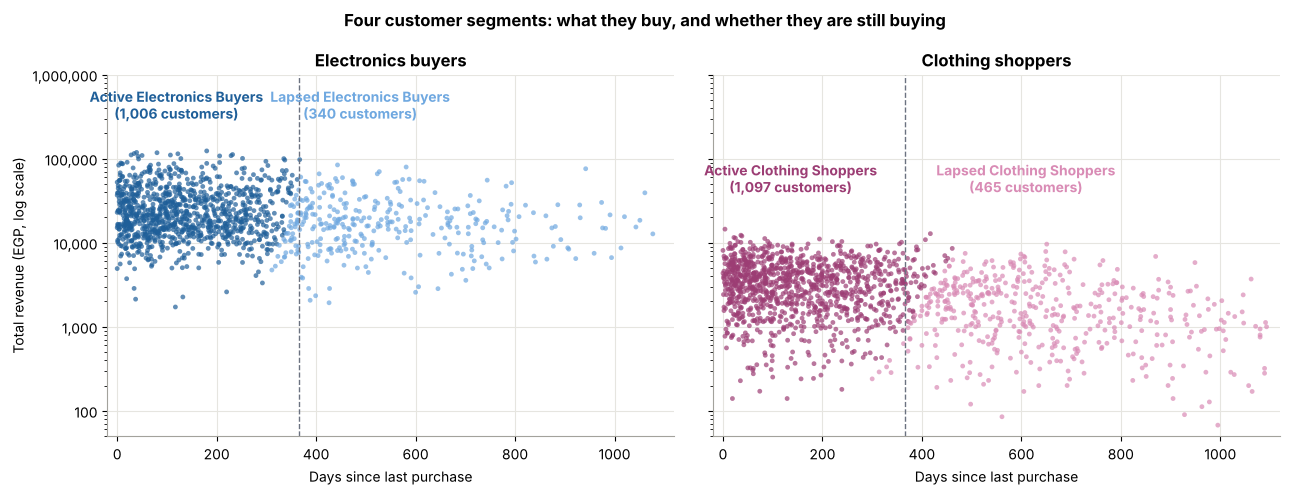

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
panels = [
    ("Electronics buyers", ["Active Electronics Buyers", "Lapsed Electronics Buyers"], 300_000),
    ("Clothing shoppers", ["Active Clothing Shoppers", "Lapsed Clothing Shoppers"], 40_000),
]
for ax, (title, segments, label_y) in zip(axes, panels):
    for segment in segments:
        d = buyers[buyers["segment"] == segment]
        ax.scatter(d["recency_days"], d["total_revenue"], s=12, alpha=0.7,
                   color=SEGMENT_COLORS[segment], edgecolor="none")
        ax.text(d["recency_days"].median(), label_y,
                f"{segment}\n({len(d):,} customers)", color=SEGMENT_COLORS[segment],
                ha="center", fontweight="bold", fontsize=10)
    ax.axvline(365, color=MUTED, linestyle="--", linewidth=1)
    ax.set_yscale("log")
    ax.set(title=title, xlabel="Days since last purchase", xlim=(-20, 1120))
axes[0].set_ylabel("Total revenue (EGP, log scale)")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_ylim(50, 1_000_000)
fig.suptitle("Four customer segments: what they buy, and whether they are still buying",
             fontweight="bold")
plt.tight_layout()
plt.show()

The split is easy to see: a typical Electronics buyer spends around **6× more** than a typical Clothing shopper, and within each group, recency separates customers who are still active from those who have drifted away.

# Segment Profiles

**Research question 2:** what is each segment worth?

In [16]:
segment_profile = (
    buyers.groupby("segment")
    .agg(
        customers=("customer_id", "size"),
        revenue=("total_revenue", "sum"),
        profit=("total_profit", "sum"),
        median_revenue=("total_revenue", "median"),
        median_profit=("total_profit", "median"),
        median_orders=("orders", "median"),
        median_recency_days=("recency_days", "median"),
        median_electronics_share=("electronics_share", "median"),
        median_margin=("profit_margin", "median"),
        average_discount=("average_discount", "mean"),
        deep_discount_share=("deep_discount_share", "mean"),
        loss_making_customers=("total_profit", lambda p: (p < 0).sum()),
    )
    .reindex(SEGMENT_ORDER)
)
segment_profile["share_of_customers"] = segment_profile["customers"] / segment_profile["customers"].sum()
segment_profile["share_of_revenue"] = segment_profile["revenue"] / segment_profile["revenue"].sum()
segment_profile["share_of_profit"] = segment_profile["profit"] / segment_profile["profit"].sum()

segment_profile.T.style.format(
    lambda v: f"{v:,.2f}" if isinstance(v, float) else v
)

segment,Active Electronics Buyers,Lapsed Electronics Buyers,Active Clothing Shoppers,Lapsed Clothing Shoppers
customers,"1,006.00",340.00,"1,097.00",465.00
revenue,"28,184,854.50","6,928,050.50","4,017,173.00","926,222.50"
profit,"5,084,854.50","1,181,600.50","1,822,343.00","430,142.50"
median_revenue,"21,227.25","16,686.00","3,293.50","1,504.00"
median_profit,"4,153.00","2,742.25","1,489.50",692.00
median_orders,4.00,3.00,3.00,2.00
median_recency_days,119.00,488.50,136.00,609.00
median_electronics_share,0.85,0.87,0.00,0.00
median_margin,0.21,0.19,0.47,0.48
average_discount,7.49,8.21,7.37,7.10


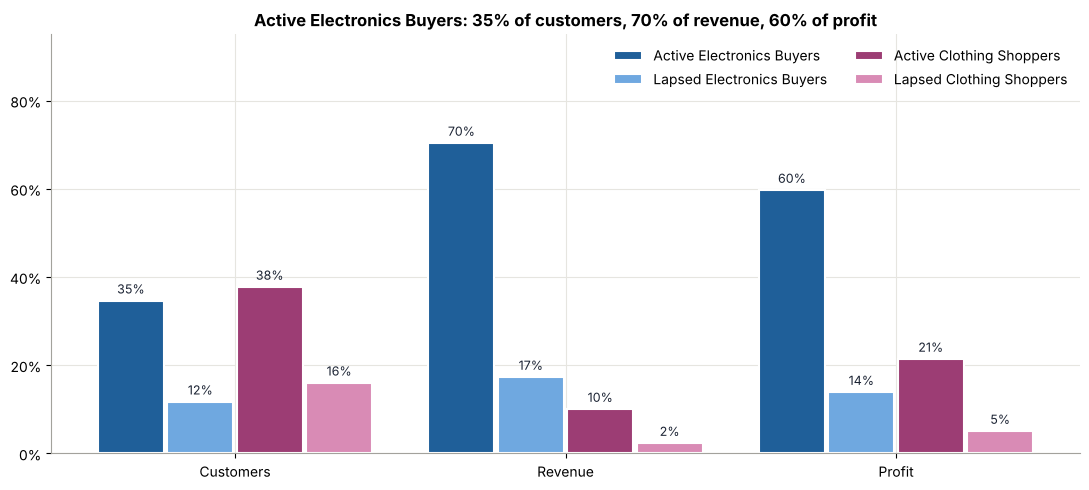

In [17]:
measures = ["share_of_customers", "share_of_revenue", "share_of_profit"]
measure_labels = ["Customers", "Revenue", "Profit"]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(measures))
width = 0.2
for i, segment in enumerate(SEGMENT_ORDER):
    values = segment_profile.loc[segment, measures].to_numpy(dtype=float)
    bars = ax.bar(x + (i - 1.5) * (width + 0.01), values, width,
                  color=SEGMENT_COLORS[segment], label=segment, edgecolor="white", linewidth=1.5)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.0%}",
                ha="center", va="bottom", fontsize=9, color="#1B2333")

ax.set_xticks(x, measure_labels)
ax.yaxis.set_major_formatter(percent)
ax.set_ylim(0, 0.95)
ax.set_title("Active Electronics Buyers: 35% of customers, 70% of revenue, 60% of profit")
ax.legend(frameon=False, ncol=2, loc="upper right")
plt.tight_layout()
plt.savefig(images_path / "segment_value.png", dpi=150, bbox_inches="tight")
plt.show()

### What each segment is, and what to do about it

In [18]:
summary_cols = ["customers", "share_of_customers", "share_of_revenue", "share_of_profit",
                "median_revenue", "median_margin", "median_recency_days", "loss_making_customers"]
segment_profile[summary_cols].style.format({
    "customers": "{:,.0f}", "share_of_customers": "{:.0%}", "share_of_revenue": "{:.0%}",
    "share_of_profit": "{:.0%}", "median_revenue": "EGP {:,.0f}", "median_margin": "{:.0%}",
    "median_recency_days": "{:,.0f} days", "loss_making_customers": "{:,.0f}",
})

,customers,share_of_customers,share_of_revenue,share_of_profit,median_revenue,median_margin,median_recency_days,loss_making_customers
segment,,,,,,,,
Active Electronics Buyers,"1,006",35%,70%,60%,"EGP 21,227",21%,119 days,17
Lapsed Electronics Buyers,340,12%,17%,14%,"EGP 16,686",19%,488 days,9
Active Clothing Shoppers,"1,097",38%,10%,21%,"EGP 3,294",47%,136 days,0
Lapsed Clothing Shoppers,465,16%,2%,5%,"EGP 1,504",48%,609 days,1


| Segment | Who they are | What they're worth | Recommended action |
|---|---|---|---|
| **Active Electronics Buyers** | Buy mostly Electronics; last purchase about 4 months ago | **35% of customers, 70% of revenue, 60% of profit**; ~EGP 21,000 each | **Protect.** Priority service, early access to new models, warranty and accessory bundles. Avoid deep discounts: their margin is only ~21%. |
| **Lapsed Electronics Buyers** | Same buying pattern, but no purchase for over a year | **12% of customers, 17% of revenue, 14% of profit** | **Win back.** Targeted re-engagement with trade-in or upgrade offers capped at 15% off, the limit at which Electronics stay profitable. |
| **Active Clothing Shoppers** | Buy Clothing only; active in the last few months | **38% of customers but 21% of profit** from only 10% of revenue; ~47% margin | **Grow.** The most profitable shoppers per EGP sold. Cross-sell accessories and outerwear, and reward repeat visits. |
| **Lapsed Clothing Shoppers** | Clothing only; no purchase in over a year and a half | **16% of customers, 2% of revenue, 5% of profit** | **Low-cost reactivation.** Automated email or SMS campaigns only, with no expensive incentives. |

Alongside these four groups, the **92 "Registered, never purchased"** customers are a separate **first-purchase opportunity**: a welcome offer on high-margin Clothing is the cheapest way to convert them.

### Do loyalty tiers match customer value?

Lotus Group already groups customers into loyalty tiers. If the tiers reflected value, Platinum members would sit mainly in the most valuable segment.

In [19]:
tier_order = ["Bronze", "Silver", "Gold", "Platinum"]

tier_value = (
    buyers.groupby("loyalty_tier")
    .agg(customers=("customer_id", "size"),
         average_revenue=("total_revenue", "mean"),
         average_profit=("total_profit", "mean"))
    .reindex(tier_order)
)
tier_mix = pd.crosstab(buyers["loyalty_tier"], buyers["segment"], normalize="index").reindex(
    index=tier_order, columns=SEGMENT_ORDER)

tier_value.style.format({"customers": "{:,.0f}", "average_revenue": "EGP {:,.0f}",
                         "average_profit": "EGP {:,.0f}"})

,customers,average_revenue,average_profit
loyalty_tier,,,
Bronze,"1,494","EGP 13,434","EGP 2,895"
Silver,857,"EGP 14,099","EGP 2,906"
Gold,427,"EGP 14,395","EGP 3,093"
Platinum,130,"EGP 13,511","EGP 2,944"


In [20]:
tier_mix.style.format("{:.0%}")

segment,Active Electronics Buyers,Lapsed Electronics Buyers,Active Clothing Shoppers,Lapsed Clothing Shoppers
loyalty_tier,,,,
Bronze,34%,12%,39%,15%
Silver,33%,12%,36%,18%
Gold,39%,11%,36%,15%
Platinum,33%,12%,40%,15%


**Takeaway:** **Loyalty tiers don't reflect customer value.** Platinum members spend and earn about the same on average as Bronze members, and every tier has roughly the same mix of segments. The current tier system rewards something other than value, so the business may be giving its best perks to customers who aren't its most valuable. These value segments offer a better basis for allocating loyalty benefits.

# Saving the Segment Assignments

We save one row per customer with their segment, including the "Registered, never purchased" group, so later work and the business can use the labels directly.

In [21]:
segments_out = pd.concat([
    buyers[["customer_id", "segment"]],
    never_purchased[["customer_id"]].assign(segment="Registered, never purchased"),
], ignore_index=True)

segments_out = segments_out.merge(
    customer_features[["customer_id", "total_revenue", "total_profit", "orders",
                       "recency_days", "electronics_share", "loyalty_tier"]],
    on="customer_id", how="left", validate="one_to_one",
)

segments_out.to_csv(outputs_path / "customer_segments.csv", index=False)
print("Saved customer_segments.csv:", segments_out.shape)
segments_out["segment"].value_counts()

Saved customer_segments.csv: (3000, 8)

segment
Active Clothing Shoppers       1097
Active Electronics Buyers      1006
Lapsed Clothing Shoppers        465
Lapsed Electronics Buyers       340
Registered, never purchased      92

# Segmentation Summary

| | |
|---|---|
| **Method** | K-Means clustering on log revenue, Electronics share and recency (standardised) |
| **Segments** | 4 behavioural segments, plus "Registered, never purchased" |
| **Quality** | Silhouette 0.46 (target ≥ 0.30); smallest segment 12% (target ≥ 5%); ARI ≈ 1 across seeds and resamples |
| **Headline** | **Active Electronics Buyers are 35% of customers but bring in 70% of revenue and 60% of profit** |
| **Hidden value** | **Active Clothing Shoppers** bring in only 10% of revenue but 21% of profit, at a ~47% margin |
| **Win-back target** | **Lapsed Electronics Buyers**: 340 customers who spent EGP 6.9M but haven't bought in over a year |
| **Surprise** | Loyalty tiers bear no relation to customer value |

**Outputs:** `01_Data/outputs/customer_segments.csv` and `05_Images/segment_value.png`.

**Next step:** Machine Learning Part B, detecting loss-making orders before they happen.